   Tenure  MonthlyCharges  Churn
0      39            1033      1
1      52             926      1
2      29            1053      1
3      15             250      0
4      43            1888      1


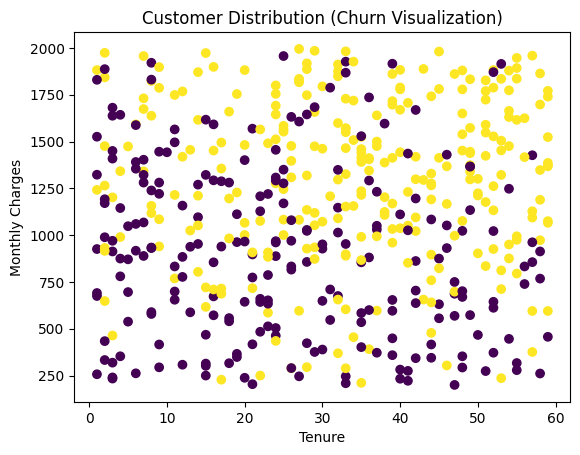


Accuracy: 0.67


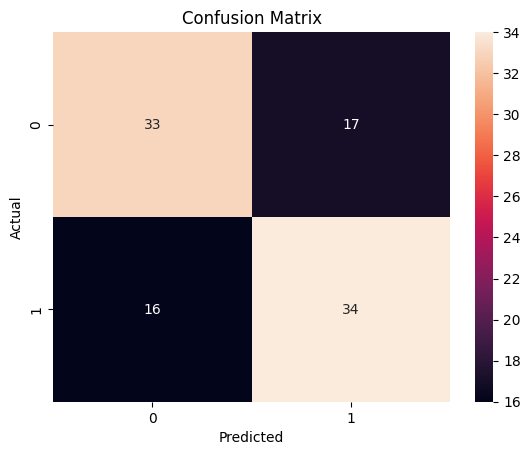


Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.66      0.67        50
           1       0.67      0.68      0.67        50

    accuracy                           0.67       100
   macro avg       0.67      0.67      0.67       100
weighted avg       0.67      0.67      0.67       100

Tenure: Coefficient = 0.6733, Odds Ratio = 1.9606
MonthlyCharges: Coefficient = 0.8701, Odds Ratio = 2.3872


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Generate reproducible customer data
np.random.seed(42)

n = 500

tenure = np.random.randint(1, 60, n)
monthly_charges = np.random.randint(200, 2000, n)

probability = 1 / (
    1 + np.exp(
        -(-3 + 0.03 * tenure + 0.002 * monthly_charges)
    )
)

churn = np.random.binomial(1, probability)

df = pd.DataFrame({
    "Tenure": tenure,
    "MonthlyCharges": monthly_charges,
    "Churn": churn
})

print(df.head())

# Plot generated data
plt.scatter(
    df["Tenure"],
    df["MonthlyCharges"],
    c=df["Churn"]
)

plt.xlabel("Tenure")
plt.ylabel("Monthly Charges")
plt.title("Customer Distribution (Churn Visualization)")
plt.show()

# Split features and target
X = df[["Tenure", "MonthlyCharges"]]
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train logistic regression
model = LogisticRegression().fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Classification report
print(
    "\nClassification Report:\n",
    classification_report(y_test, y_pred)
)

# Interpret coefficients as odds ratios
for name, coef in zip(
    ["Tenure", "MonthlyCharges"],
    model.coef_[0]
):

    print(
        f"{name}: Coefficient = {coef:.4f}, "
        f"Odds Ratio = {np.exp(coef):.4f}"
    )